> **Notebook obsolète.** Il utilise un découpage aléatoire 80 / 20, et la sélection des features y est faite avant le découpage. Les scores obtenus ici sont donc optimistes. Ce découpage a été abandonné au profit de celui de l'énoncé (2000 premiers cycles / 205 derniers) : voir la section 3.1 de `notebook_projet.ipynb`.

# Ensemble learning

Objectif : tester des modèles d'ensemble et les comparer aux modèles simples (régression logistique, k plus proches voisins, arbre de décision, Naive Bayes, SVM).

Un modèle d'ensemble combine plusieurs modèles pour prendre une seule décision. L'idée : plusieurs modèles qui se trompent sur des cycles différents se trompent moins souvent ensemble qu'un modèle seul.

On teste les trois grandes familles :

| Famille | Modèles | Principe | Ce que ça corrige |
|---|---|---|---|
| Bagging | `bagging`, `random_forest`, `extra_trees` | beaucoup d'arbres entraînés chacun sur un tirage aléatoire du train, puis vote | la variance : un arbre seul change beaucoup si les données changent un peu |
| Boosting | `adaboost`, `gradient_boosting` | des modèles simples ajoutés un par un, chacun se concentre sur les erreurs des précédents | le biais : des modèles trop simples |
| Combinaison | `vote_soft`, `stacking` | régression logistique, k plus proches voisins, SVM et forêt aléatoire décident ensemble | profite de modèles de natures différentes |

`vote_soft` fait la moyenne des probabilités des 4 modèles. `stacking` apprend avec une régression logistique comment pondérer leurs avis.

Les jeux de données sont ceux de `data/processed/` (découpage aléatoire 80 / 20). Le découpage imposé par l'énoncé est traité dans `decoupage_enonce.ipynb`.

## 1. Imports

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_processed, save_figure, FEATURE_SETS
from src.model import get_baseline_models, get_ensemble_models
from src.train import compare_models
from src.evaluation import plot_confusion_matrices, plot_roc_curves

# Avertissements de convergence et de version sans impact sur les résultats
warnings.filterwarnings("ignore")

## 2. Les modèles comparés

Tous les modèles gardent leurs réglages par défaut (définis dans `src/model.py`), pour comparer les familles à armes égales. L'optimisation des hyperparamètres est faite à part (`model_training.ipynb` et `notebook_projet.ipynb`).

In [2]:
def tous_les_modeles():
    """Les modèles simples puis les 7 modèles d'ensemble, avec leur famille."""
    simples = get_baseline_models()
    simples.pop("random_forest")          # déjà présent dans les ensembles
    ensembles = get_ensemble_models()
    familles = {nom: "simple" for nom in simples}
    familles.update({"bagging": "bagging", "random_forest": "bagging", "extra_trees": "bagging",
                     "adaboost": "boosting", "gradient_boosting": "boosting",
                     "vote_soft": "combinaison", "stacking": "combinaison"})
    return {**simples, **ensembles}, familles

modeles, familles = tous_les_modeles()
pd.Series(familles, name="famille").to_frame()

,famille
knn,simple
decision_tree,simple
logistic_regression,simple
naive_bayes,simple
svm,simple
bagging,bagging
random_forest,bagging
extra_trees,bagging
adaboost,boosting
gradient_boosting,boosting


## 3. Comparaison sur le jeu histogramme

On commence par le jeu `histogramme`, le meilleur jeu de features jusqu'ici.

Pour chaque modèle, `compare_models` calcule :

- `train_f1_macro` : score sur les données d'entraînement elles-mêmes ;
- `cv_f1_macro` et `cv_std` : moyenne et écart type du score en validation croisée à 5 plis sur le train ;
- les scores sur le test (`accuracy`, `f1_macro`, `auc`, etc.), calculés une seule fois ;
- `fit_time_s` : temps d'entraînement en secondes.

Un grand écart entre `train_f1_macro` et `cv_f1_macro` signale un surapprentissage (variance). Deux scores bas signalent un modèle trop simple (biais).

In [3]:
x_train, x_test, y_train, y_test = load_processed("histogramme")

resultats, entraines = compare_models(modeles, x_train, y_train, x_test, y_test)
resultats.insert(0, "famille", resultats.index.map(familles))

colonnes = ["famille", "train_f1_macro", "cv_f1_macro", "cv_std", "accuracy", "f1_macro", "auc", "fit_time_s"]
resultats[colonnes].round(3)

,famille,train_f1_macro,cv_f1_macro,cv_std,accuracy,f1_macro,auc,fit_time_s
model,,,,,,,,
adaboost,boosting,1.000,0.999,0.001,1.000,1.000,1.000,1.371
decision_tree,simple,1.000,0.997,0.003,0.998,0.998,0.998,0.008
bagging,bagging,1.000,0.997,0.003,0.998,0.998,1.000,2.281
gradient_boosting,boosting,1.000,0.998,0.002,0.998,0.998,1.000,2.372
extra_trees,bagging,1.000,0.996,0.001,0.995,0.995,1.000,1.760
random_forest,bagging,1.000,0.998,0.001,0.995,0.995,1.000,1.036
logistic_regression,simple,0.990,0.987,0.004,0.991,0.991,0.998,0.026
stacking,combinaison,0.998,0.995,0.002,0.991,0.991,1.000,6.176
vote_soft,combinaison,0.997,0.994,0.003,0.986,0.986,0.999,1.487


Score moyen par famille :

In [4]:
resultats.groupby("famille")[["cv_f1_macro", "f1_macro", "fit_time_s"]].mean().sort_values("f1_macro", ascending=False).round(3)

,cv_f1_macro,f1_macro,fit_time_s
famille,,,
boosting,0.999,0.999,1.872
bagging,0.997,0.996,1.693
combinaison,0.995,0.989,3.831
simple,0.959,0.955,0.020


## 4. Matrices de confusion et courbes ROC des modèles d'ensemble

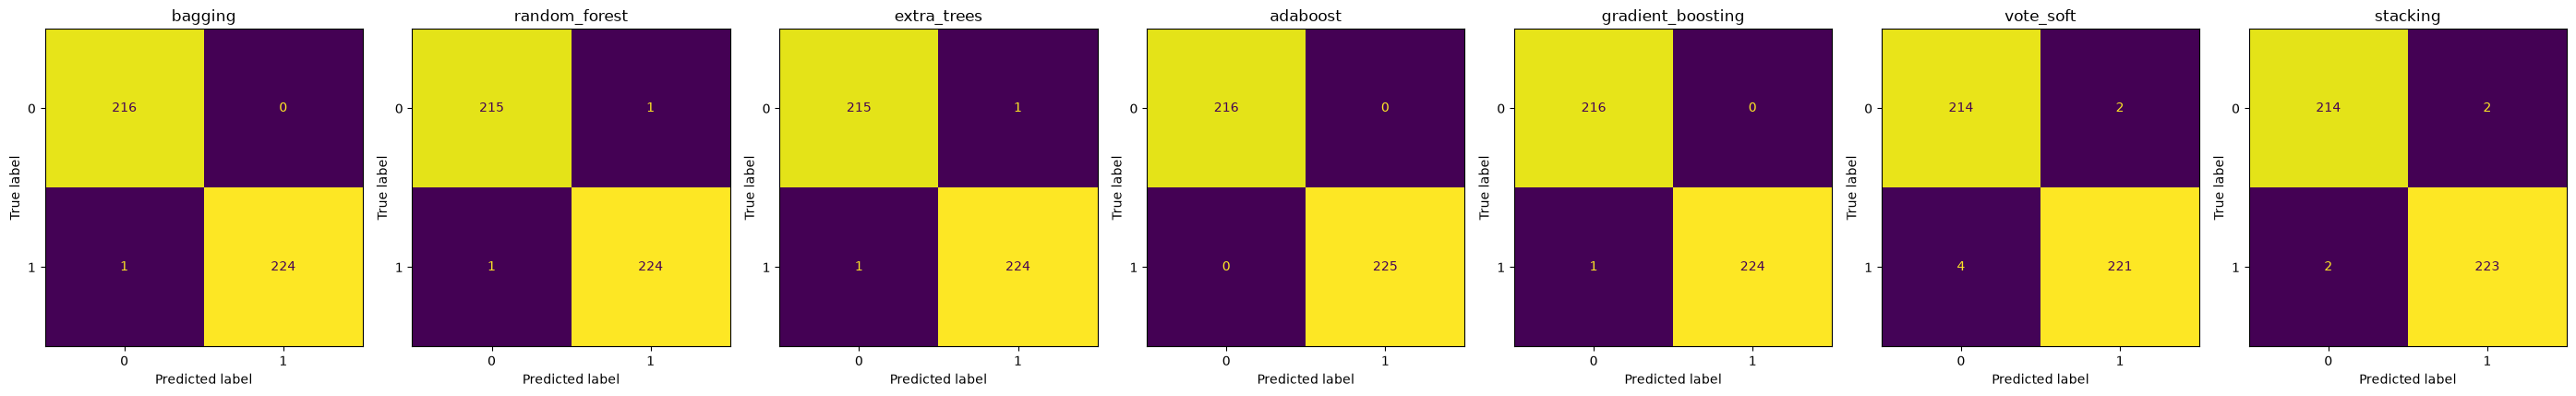

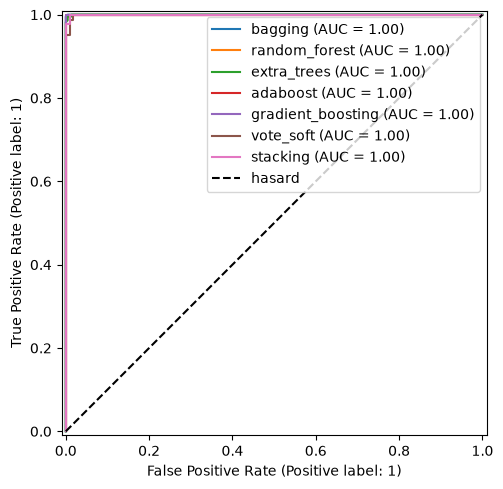

In [5]:
ensembles = {nom: entraines[nom] for nom in get_ensemble_models()}

plot_confusion_matrices(ensembles, x_test, y_test, save_as="matrices_confusion_ensembles_histogramme.png")
plot_roc_curves(ensembles, x_test, y_test, save_as="courbes_roc_ensembles_histogramme.png")

## 5. Les 4 jeux de features

On refait la même comparaison sur les 4 jeux de `data/processed/`, pour voir si les ensembles aident partout ou seulement sur certains jeux.

In [6]:
f1_test = {}
for nom in FEATURE_SETS:
    x_tr, x_te, y_tr, y_te = load_processed(nom)
    modeles, _ = tous_les_modeles()                      # modèles neufs pour chaque jeu
    res, _ = compare_models(modeles, x_tr, y_tr, x_te, y_te)
    f1_test[nom] = res["f1_macro"]

f1_test = pd.DataFrame(f1_test)
f1_test.insert(0, "famille", f1_test.index.map(familles))
f1_test = f1_test.sort_values(["famille", "histogramme"], ascending=[True, False])
f1_test.round(3)

,famille,stats,spectre,stats_spectre,histogramme
model,,,,,
bagging,bagging,0.975,0.975,0.973,0.998
extra_trees,bagging,0.984,0.977,0.991,0.995
random_forest,bagging,0.984,0.975,0.980,0.995
adaboost,boosting,0.850,0.966,0.966,1.000
gradient_boosting,boosting,0.984,0.977,0.991,0.998
stacking,combinaison,0.982,0.977,0.991,0.991
vote_soft,combinaison,0.943,0.952,0.984,0.986
decision_tree,simple,0.964,0.975,0.973,0.998
logistic_regression,simple,0.712,0.823,0.943,0.991


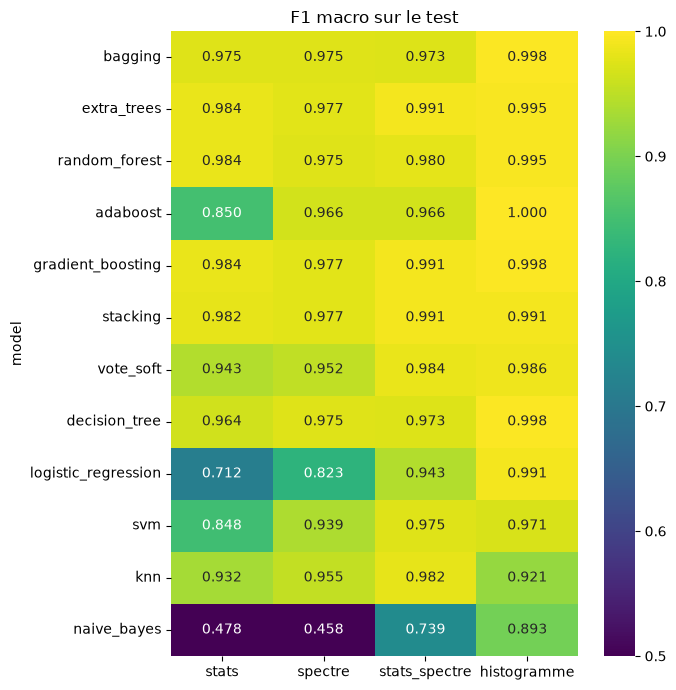

In [7]:
# F1 macro sur le test : une ligne par modèle, une colonne par jeu de features
plt.figure(figsize=(7, 7))
sns.heatmap(f1_test[FEATURE_SETS], annot=True, fmt=".3f", cmap="viridis", vmin=0.5, vmax=1)
plt.title("F1 macro sur le test")
save_figure("f1_ensembles_par_jeu.png")
plt.show()

In [8]:
# Meilleur modèle simple contre meilleur modèle d'ensemble, pour chaque jeu
est_simple = f1_test["famille"] == "simple"
pd.DataFrame({
    "meilleur simple": f1_test.loc[est_simple, FEATURE_SETS].max(),
    "modèle simple": f1_test.loc[est_simple, FEATURE_SETS].idxmax(),
    "meilleur ensemble": f1_test.loc[~est_simple, FEATURE_SETS].max(),
    "modèle d'ensemble": f1_test.loc[~est_simple, FEATURE_SETS].idxmax(),
}).round(3)

,meilleur simple,modèle simple,meilleur ensemble,modèle d'ensemble
stats,0.964,decision_tree,0.984,extra_trees
spectre,0.975,decision_tree,0.977,extra_trees
stats_spectre,0.982,knn,0.991,extra_trees
histogramme,0.998,decision_tree,1.000,adaboost


## 6. Conclusion

**1. Un ensemble fait toujours au moins aussi bien que le meilleur modèle simple.** Le gain est le plus net là où les modèles simples ont du mal : sur `stats`, le meilleur modèle simple (arbre de décision) obtient 0.964 de F1 sur le test, extra trees monte à 0.984. Sur `histogramme`, un arbre seul atteint déjà 0.998 : il reste peu de place pour progresser.

**2. Bagging et boosting sont les familles les plus fiables.** Ils dépassent 0.97 de F1 sur presque tous les jeux. AdaBoost est la seule exception : 0.850 sur `stats`, car ses arbres d'une seule coupe sont trop simples pour ces features.

**3. Le vote et le stacking ne valent pas le coup ici.** Ils combinent des modèles forts (forêt aléatoire) et des modèles plus faibles (k plus proches voisins, SVM), et la moyenne tire le résultat vers le bas. Ce sont aussi les plus lents : environ 6 secondes d'entraînement pour le stacking, contre moins d'une seconde pour un arbre.

**4. Biais et variance.** Les modèles à base d'arbres ont un score de 1.000 sur le train et entre 0.996 et 0.999 en validation croisée : ils apprennent le train par coeur, mais généralisent quand même très bien, donc peu de variance. La régression logistique a des scores proches sur le train et en validation (0.990 et 0.987) : léger biais, aucune variance. Les k plus proches voisins perdent 3 points entre le train et la validation : c'est le modèle le plus sujet à la variance.

**Limite.** Avec un découpage aléatoire, les cycles du test ressemblent beaucoup à ceux du train, et tous les bons modèles dépassent 0.99. Une différence de 0.002, c'est un seul cycle sur 441 : ce n'est pas significatif. Le découpage imposé par l'énoncé, plus exigeant, départage mieux les modèles. Voir `decoupage_enonce.ipynb`.

**Pour la suite** : jeu de features `histogramme`, avec un modèle de boosting ou de bagging.